## Configuration


In [109]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("../src")
from genera_datos import generar_datos, resumen

USAR_SINTETICOS = True   

if USAR_SINTETICOS:
    from genera_datos import generar_datos
    participacions, carreiras = generar_datos()
else:
    participacions = pd.read_csv("../datos/clean/participacions.csv")
    carreiras = pd.read_csv("../datos/clean/carreiras.csv")

In [110]:
print(participacions.head())
print(carreiras.head())

  persona_id  id_carrera  orden sexo   categoria  tipo_participante  tiempo_s  \
0      I0001  carrera_01      1    M  Veterano A  inscrito_circuito    3317.0   
1      I0002  carrera_01      1    M  Veterano B  inscrito_circuito    3669.0   
2      I0003  carrera_01      1    M      Senior  inscrito_circuito    3876.0   
3      I0004  carrera_01      1    F  Veterano B  inscrito_circuito    3773.0   
4      I0005  carrera_01      1    M      Senior  inscrito_circuito    2616.0   

  tiempo_estado  puesto_general  puesto_sexo  puesto_categoria  
0        valido              75           66                17  
1        valido             139          108                15  
2        valido             171          128                56  
3        valido             157           36                 7  
4        valido               3            3                 2  
   id_carrera  orden      fecha  distancia_km
0  carrera_01      1 2026-01-18          10.3
1  carrera_02      2 2026-03-01

## Participación
1. Participantes por sexo en cada carreira e evolución ao longo do circuíto.


In [111]:
print(participacions["sexo"])

# unstack() hace un pivot , porque sino tendriamos dos indices que serian sexo e id_carrera 
# al hacerlo pasamos que el id_carrera sea columnas y el sexo el indice, y si no forzamos
participacion_agrupado = participacions.groupby(["id_carrera","sexo"])["persona_id"].nunique().unstack()
print(participacion_agrupado)

0       M
1       M
2       M
3       F
4       M
       ..
1599    M
1600    M
1601    M
1602    F
1603    M
Name: sexo, Length: 1604, dtype: str
sexo         F    M
id_carrera         
carrera_01  76  146
carrera_02  74  145
carrera_03  60  151
carrera_04  90  131
carrera_05  64  125
carrera_06  60  126
carrera_07  57  118
carrera_08  65  116


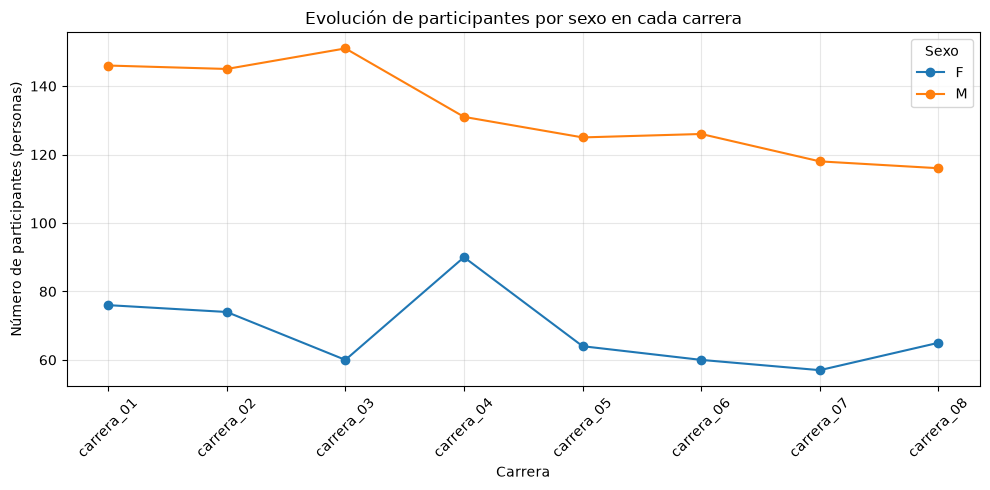

In [112]:
participacion_agrupado.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Evolución de participantes por sexo en cada carrera")
plt.xlabel("Carrera")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En esta gráfica observamos una disminucion progresiva de las personas masculinas a lo largo de la carerra, en cambio con respeto a la categoría femenina observamos tambien una disminucion con respecto a la primera y ultima carrera

2. Distribución por categorías de idade e diferenza entre sexos dentro de cada categoría.

In [113]:
print(participacions["categoria"])

participacions_idade = participacions.groupby(["categoria","sexo"])["persona_id"].nunique().unstack()

print(participacions_idade)

0       Veterano A
1       Veterano B
2           Senior
3       Veterano B
4           Senior
           ...    
1599        Senior
1600    Veterano B
1601        Senior
1602    Veterano A
1603        Senior
Name: categoria, Length: 1604, dtype: str
sexo         F    M
categoria          
Promesa     20   33
Senior      81  161
Veterano A  64  120
Veterano B  53   67
Veterano C  14   36


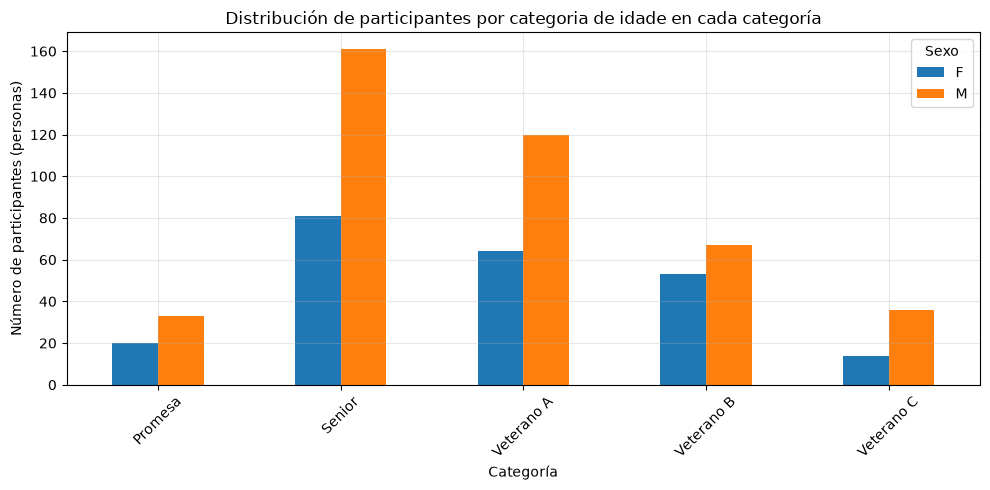

In [114]:
participacions_idade.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribución de participantes por categoria de idade en cada categoría")
plt.xlabel("Categoría")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Inscritos no circuíto e corredores por proba
1. En cada carreira, que porcentaxe de participantes están inscritos no circuíto e que porcentaxe corren por proba? Cambia ao longo do ano?

In [115]:
participacions_tipo = participacions.groupby(["id_carrera","tipo_participante"])["persona_id"].nunique().unstack().fillna(0)

participacions_tipo = participacions_tipo.drop(columns="no_resuelto")
# axis = 1 hace que opere horizontalmente
# Divide cada valor de una fila entre el total de esa carrera (axis = 0).
porcentajes = participacions_tipo.div(
    participacions_tipo.sum(axis=1), axis=0
) * 100

print(porcentajes.round(2))

tipo_participante  inscrito_circuito  por_prueba
id_carrera                                      
carrera_01                     60.91       39.09
carrera_02                     58.72       41.28
carrera_03                     59.52       40.48
carrera_04                     50.68       49.32
carrera_05                     60.87       39.13
carrera_06                     54.59       45.41
carrera_07                     52.91       47.09
carrera_08                     49.72       50.28


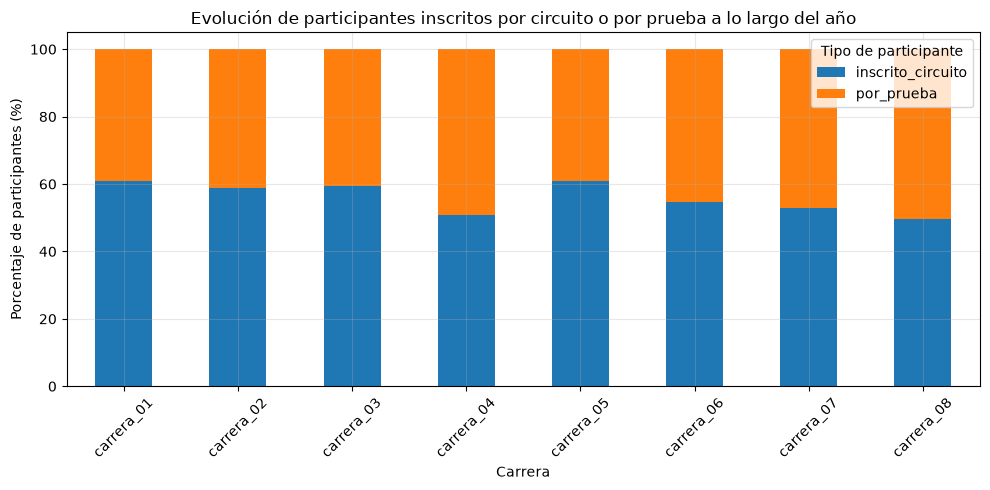

In [116]:
porcentajes.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Evolución de participantes inscritos por circuito o por prueba a lo largo del año")
plt.xlabel("Carrera")
plt.ylabel("Porcentaje de participantes (%)")
plt.legend(title="Tipo de participante")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2. En cantas carreiras participa de media unha persoa inscrita no circuíto? Cantas corren todas as carreiras, cantas abandonan e en que momento?

In [117]:
inscritos = participacions[
    participacions["tipo_participante"] == "inscrito_circuito"
]

# Agrupamos por persona y miramos la columna id_carrera con las no repetidas, 
# entonces tenemos las carreras por personas
carrera_por_persona = inscritos.groupby(
    "persona_id"
)["id_carrera"].nunique()

print("Cantidad de carreras de media que corren los inscritos en el circuito:",carrera_por_persona.mean())

# Total de carreras
total_carreras = carreiras["id_carrera"].nunique()

# Miramos si por carrera por personas es igual al numero total de carreras, para ver 
# cuantas personas completan todas las carreras.
completan = carrera_por_persona[
    carrera_por_persona == total_carreras
]

print("Personas que completan todas:", len(completan))

# Agrupamos los inscritos por persona, entonces tenemos una tabla por persona para ver el total de cada una en cada dato,
# Añadimos dos columnas nuevas una para ver la ultima carrera participada, y el numero de carreras participadas

ultima_participacion = inscritos.groupby(
    "persona_id"
).agg(
    ultima_carrera=("orden", "max"),
    numero_carreras=("id_carrera", "nunique")
)

# Ultima carrera 
ultima_carrera_circuito = participacions["orden"].max()

# Abandono aparente , porque no podemos confirmar que por dejar de ir a una carrea hayan abandonado.
# Miramos si la ultima carrera de cada persona es menor a la ultima carrera de circuito.
abandonos_aparentes = ultima_participacion[
    ultima_participacion["ultima_carrera"] < ultima_carrera_circuito
]

# Agrupamos por la ultima carrera y contamos el numero de abandonos por su ultima carrea hecha
abandono_por_carrera = abandonos_aparentes.groupby(
    "ultima_carrera"
).size()

print("Personas que dejan de aparecer:", len(abandonos_aparentes))
print(abandono_por_carrera)


Cantidad de carreras de media que corren los inscritos en el circuito: 5.993288590604027
Personas que completan todas: 42
Personas que dejan de aparecer: 59
ultima_carrera
1     7
2    10
3     9
4     5
5     8
6     7
7    13
dtype: int64


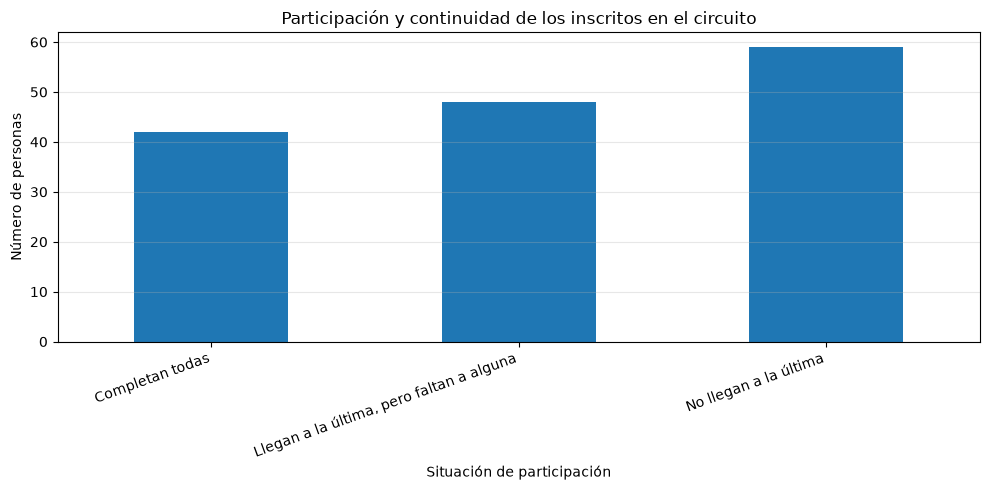

In [118]:
# Personas que completan todas las carreras
completan_todas = len(completan)

llegan_ultima = ultima_participacion[
    ultima_participacion["ultima_carrera"] == ultima_carrera_circuito
]

# Llegan a la última, pero no completan todas
llegan_pero_no_completan = (
    len(llegan_ultima) - completan_todas
)

# Dejan de aparecer antes de la última
no_llegan_ultima = len(abandonos_aparentes)

datos = pd.Series({
    "Completan todas": completan_todas,
    "Llegan a la última, pero faltan a alguna": llegan_pero_no_completan,
    "No llegan a la última": no_llegan_ultima
})

datos.plot(kind="bar", figsize=(10, 5))

plt.title("Participación y continuidad de los inscritos en el circuito")
plt.xlabel("Situación de participación")
plt.ylabel("Número de personas")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

3. Repiten as persoas que corren por proba? Hai quen corre varias carreiras sen inscribirse no circuíto?

In [125]:
inscritos_proba = participacions[participacions["tipo_participante"] == "por_prueba"]

carreras_por_persona_prueba = inscritos_proba.groupby("persona_id")["id_carrera"].nunique()

print("Cantidad de personas inscritas por prueba que repiten:",len(carreras_por_persona_prueba[carreras_por_persona_prueba > 1]))

Cantidad de personas inscritas por prueba que repiten: 140


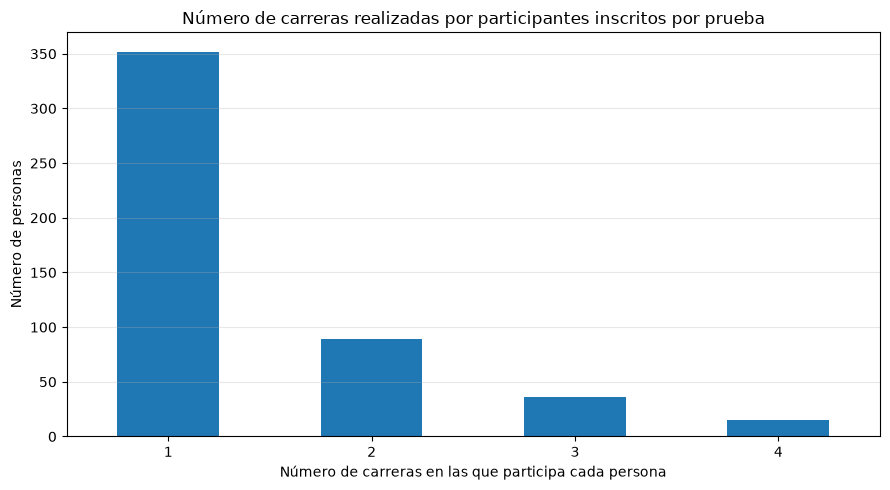

In [126]:
distribucion = carreras_por_persona_prueba.value_counts().sort_index()

distribucion.plot(kind="bar", figsize=(9, 5))

plt.title("Número de carreras realizadas por participantes inscritos por prueba")
plt.xlabel("Número de carreras en las que participa cada persona")
plt.ylabel("Número de personas")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

4. Hai diferenzas por sexo e categoría entre inscritos no circuíto e corredores por proba?

In [132]:
circuito = inscritos.groupby(["sexo","categoria"])["persona_id"].nunique().unstack()
por_proba = inscritos_proba.groupby(["sexo","categoria"])["persona_id"].nunique().unstack()

print(circuito)
print()
print(por_proba)

categoria  Promesa  Senior  Veterano A  Veterano B  Veterano C
sexo                                                          
F                3      24          10           7           3
M                9      37          25          21          10

categoria  Promesa  Senior  Veterano A  Veterano B  Veterano C
sexo                                                          
F               17      56          53          46          11
M               23     123          92          45          26


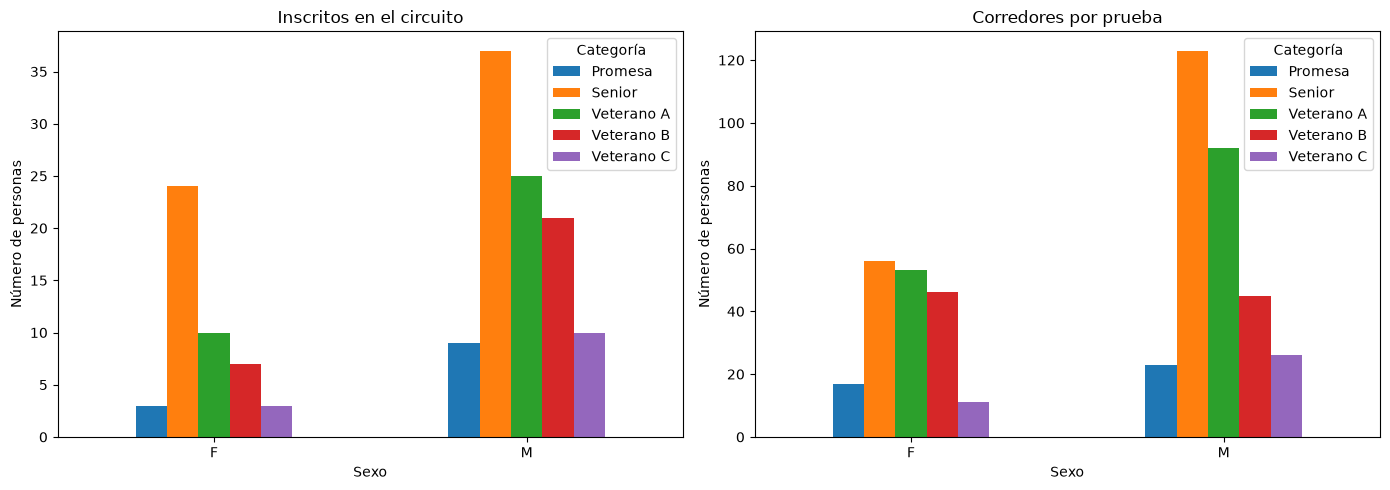

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

circuito.plot(kind="bar", ax=axes[0])
axes[0].set_title("Inscritos en el circuito")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Número de personas")
axes[0].legend(title="Categoría")
axes[0].tick_params(axis="x", rotation=0)

por_proba.plot(kind="bar", ax=axes[1])
axes[1].set_title("Corredores por prueba")
axes[1].set_xlabel("Sexo")
axes[1].set_ylabel("Número de personas")
axes[1].legend(title="Categoría")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

5. Os inscritos no circuíto quedan en mellores postos que os corredores por proba?

In [ ]:
print(inscritos["puesto_general"].mean())
print(inscritos_proba["puesto_general"].mean())

np.float64(103.84548104956268)

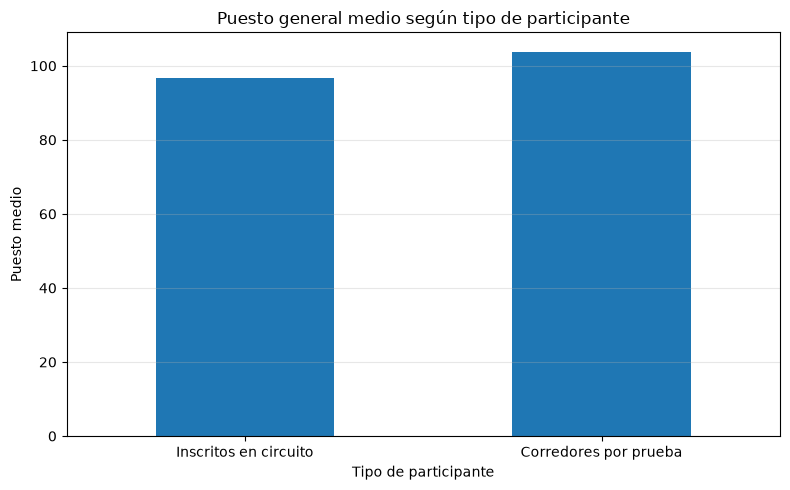

In [136]:
medias = pd.Series({
    "Inscritos en circuito": inscritos["puesto_general"].mean(),
    "Corredores por prueba": inscritos_proba["puesto_general"].mean()
})

medias.plot(kind="bar", figsize=(8, 5))

plt.title("Puesto general medio según tipo de participante")
plt.xlabel("Tipo de participante")
plt.ylabel("Puesto medio")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()